# **Leukemia Subtype Classification via Gene Expression Profiles Using BioMedGPT-LM-7B**

# **Langkah 1 - Instalasi Pustaka**

In [ ]:
!pip install -q -U bitsandbytes accelerate
!pip install -q wordcloud

import transformers, accelerate, bitsandbytes
print("transformers:", transformers.__version__)
print("accelerate  :", accelerate.__version__)
print("bitsandbytes:", bitsandbytes.__version__)

transformers: 5.22.1
accelerate  : 1.16.0
bitsandbytes: 0.50.2


In [ ]:
import gc
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.preprocessing import StandardScaler
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    GenerationConfig,
)

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Cek GPU
print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU     : {gpu.name} ({gpu.total_memory / 1024**3:.1f} GB)")
else:
    print("GPU belum aktif -> aktifkan lewat Runtime > Change runtime type.")

PyTorch : 2.14.1+cu130
CUDA    : True
GPU     : Tesla T4 (14.6 GB)


# **Langkah 2 - Konfigurasi**

Semua parameter dikumpulkan **di satu tempat**.

| Parameter | Arti |
|---|---|
| `K_GENES` | Jumlah gen terbaik yang diberikan ke LLM (dari 7.129). LLM punya batas konteks, jadi tidak mungkin memasukkan semua gen. |
| `MAX_NEW_TOKENS` | Panjang maksimum teks penjelasan yang dihasilkan LLM. |
| `PROB_THRESHOLD` | Batas keputusan: jika P(AML) > 0,5 maka diprediksi AML. |
| `CLASS_KEYWORDS` | Kata/token yang dianggap "bukti" untuk tiap kelas ketika membaca probabilitas token pertama. |
| `SPLITS_TO_RUN` | Data mana yang dijalankan: `"train"` (38 pasien), `"test"` (34 pasien). |
| `MAX_PATIENTS` | Isi angka kecil (mis. `6`) untuk uji cepat; `None` = semua pasien. |

In [ ]:
# ---------- Lokasi data ----------
ZIP_PATH   = "/content/archive.zip"
DATA_DIR   = "/content/gene_expression_data"
OUTPUT_DIR = "/content/hasil"

TRAIN_CSV  = f"{DATA_DIR}/data_set_ALL_AML_train.csv"
TEST_CSV   = f"{DATA_DIR}/data_set_ALL_AML_independent.csv"
LABELS_CSV = f"{DATA_DIR}/actual.csv"

# ---------- Kelas ----------
CLASS_NAMES  = ["ALL", "AML"]                       # indeks 0 = ALL, indeks 1 = AML
LABEL_TO_INT = {name: i for i, name in enumerate(CLASS_NAMES)}

# ---------- Preprocessing ----------
K_GENES = 10                                        # jumlah gen yang dipilih

# ---------- Model ----------
MODEL_NAME = "PharMolix/BioMedGPT-LM-7B"
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"

# Kuantisasi 4-bit: memperkecil model 7B (~14 GB) agar muat di GPU Colab T4 (15 GB)
BNB_CONFIG = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

# ---------- Inferensi ----------
MAX_PROMPT_TOKENS = 1024
MAX_NEW_TOKENS    = 200
PROB_THRESHOLD    = 0.5

# Kata yang mewakili tiap kelas pada token pertama jawaban LLM
CLASS_KEYWORDS = {
    "ALL": ["ALL", "Lymph"],
    "AML": ["AML", "Myeloid", "Ac"],
}

GENERATION_CONFIG = dict(
    max_new_tokens=MAX_NEW_TOKENS,
    do_sample=False,            # deterministik: hasil sama setiap dijalankan
    repetition_penalty=1.15,
    no_repeat_ngram_size=3,
)

# ---------- Eksekusi ----------
SPLITS_TO_RUN = ["train", "test"]
MAX_PATIENTS  = None            # contoh uji cepat: 6

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Konfigurasi siap. Device:", DEVICE)

Konfigurasi siap. Device: cuda


## **Langkah 3 — Upload dan ekstrak dataset**
Dataset yang dipakai adalah Golub et al. (1999) dari file `archive.zip`:

| File | Isi |
|---|---|
| `data_set_ALL_AML_train.csv` | Ekspresi 7.129 gen untuk 38 pasien (data latih) |
| `data_set_ALL_AML_independent.csv` | Ekspresi 7.129 gen untuk 34 pasien (data uji) |
| `actual.csv` | Label asli tiap pasien: `ALL` (47 pasien) atau `AML` (25 pasien) |

In [ ]:
if not os.path.exists(ZIP_PATH):
    from google.colab import files
    files.upload()                      # pilih archive.zip

import zipfile
os.makedirs(DATA_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)

print("File hasil ekstrak:", sorted(os.listdir(DATA_DIR)))

Saving archive.zip to archive.zip
File hasil ekstrak: ['actual.csv', 'data_set_ALL_AML_independent.csv', 'data_set_ALL_AML_train.csv']


## **Langkah 4 — Memuat dan merapikan data**
Pada file CSV, **baris = gen** dan **kolom = pasien**. Untuk klasifikasi kita butuh kebalikannya: **baris = pasien** dan **kolom = gen**. Selain itu setiap pasien punya kolom pendamping `call`, `call.1`, `call.2`, ... (penilaian kualitatif A/P/M) yang bukan nilai ekspresi dan harus dibuang.

Fungsi `load_split` melakukan 4 hal secara berurutan:
1. Baca CSV.
2. Ambil hanya kolom yang namanya **angka** (= ID pasien); kolom `call*` otomatis terbuang.
3. Transpose menjadi matriks `pasien × gen`.
4. Cocokkan label dari `actual.csv` berdasarkan ID pasien.

In [ ]:
def load_split(csv_path, label_map):
    """Muat satu file CSV ekspresi gen dan ubah menjadi matriks pasien x gen.

    Args:
        csv_path : lokasi file CSV (train atau independent/test).
        label_map: dict {id_pasien: "ALL"/"AML"} dari actual.csv.

    Returns:
        X           : array (n_pasien, n_gen) berisi nilai ekspresi.
        y           : array (n_pasien,) label 0 (ALL) atau 1 (AML).
        patient_ids : list ID pasien sesuai urutan baris X.
        gene_names  : list nomor akses gen sesuai urutan kolom X.
    """
    df = pd.read_csv(csv_path)
    gene_names = df["Gene Accession Number"].tolist()

    patient_cols = [c for c in df.columns if c.isdigit()]   # buang 'call', 'call.1', ...
    patient_ids  = [int(c) for c in patient_cols]

    X = df[patient_cols].T.values.astype(float)             # transpose -> pasien x gen
    y = np.array([LABEL_TO_INT[label_map[p]] for p in patient_ids])
    return X, y, patient_ids, gene_names


labels_df = pd.read_csv(LABELS_CSV)
label_map = dict(zip(labels_df["patient"].astype(int), labels_df["cancer"]))

X_train, y_train, train_ids, gene_names       = load_split(TRAIN_CSV, label_map)
X_test,  y_test,  test_ids,  gene_names_test  = load_split(TEST_CSV,  label_map)

assert gene_names == gene_names_test, "Urutan gen di train dan test harus sama"

print(f"Train : {X_train.shape[0]} pasien x {X_train.shape[1]} gen | "
      f"ALL={np.sum(y_train == 0)}, AML={np.sum(y_train == 1)}")
print(f"Test  : {X_test.shape[0]} pasien x {X_test.shape[1]} gen | "
      f"ALL={np.sum(y_test == 0)}, AML={np.sum(y_test == 1)}")

Train : 38 pasien x 7129 gen | ALL=27, AML=11
Test  : 34 pasien x 7129 gen | ALL=20, AML=14


## **Langkah 5 — Preprocessing: standarisasi dan pemilihan gen**

Dataset ini punya **7.129 fitur tetapi hanya 72 pasien** (masalah *curse of dimensionality*), dan LLM tidak mungkin membaca ribuan angka dalam satu prompt. Maka ada dua tahap:

1. **`StandardScaler`**: ubah tiap gen ke skala yang sama (rata-rata 0, simpangan baku 1). Nilai positif berarti ekspresi di atas rata-rata (**HIGH**), negatif di bawah rata-rata (**LOW**).
2. **`SelectKBest` + ANOVA F-test**: pilih `K_GENES` gen yang paling membedakan ALL dari AML.

> **Penting (mencegah *data leakage*):** scaler dan selector hanya di-*fit* pada **data latih**, lalu diterapkan ke data uji. Data uji tidak boleh ikut menentukan gen terpilih.

In [ ]:
def preprocess(X_train, y_train, X_test, gene_names, k):
    """Standarisasi lalu pilih k gen paling diskriminatif (fit hanya pada data latih)."""
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    selector = SelectKBest(score_func=f_classif, k=k)
    X_train_sel = selector.fit_transform(X_train_scaled, y_train)
    X_test_sel  = selector.transform(X_test_scaled)

    selected_genes = [gene_names[i] for i in selector.get_support(indices=True)]
    return X_train_sel, X_test_sel, selected_genes


X_train_sel, X_test_sel, selected_genes = preprocess(
    X_train, y_train, X_test, gene_names, K_GENES
)

print(f"{K_GENES} gen terpilih dari {X_train.shape[1]}:")
for g in selected_genes:
    print("  -", g)
print("\nBentuk data untuk LLM  ->  train:", X_train_sel.shape, "| test:", X_test_sel.shape)

10 gen terpilih dari 7129:
  - D49950_at
  - M16038_at
  - M23197_at
  - M55150_at
  - M84526_at
  - U50136_rna1_at
  - U82759_at
  - X17042_at
  - X95735_at
  - Y12670_at

Bentuk data untuk LLM  ->  train: (38, 10) | test: (34, 10)


## **Langkah 6 — Memuat model BioMedGPT-LM-7B**

BioMedGPT-LM-7B adalah LLM 7 miliar parameter yang dilatih lanjut (dari Llama-2) pada teks biomedis. Dalam bentuk aslinya ia butuh ±14 GB VRAM, hampir seluruh memori GPU T4. Karena itu dipakai **kuantisasi 4-bit (NF4)** yang menyimpan bobot dengan presisi lebih rendah sehingga hanya memakan ±4–5 GB, dengan penurunan kualitas yang kecil.

`model.eval()` mematikan mode pelatihan; kita hanya melakukan **inferensi** (tidak ada pelatihan)

In [ ]:
def load_model(model_name, bnb_config):
    """Muat tokenizer dan model (4-bit) lalu siapkan untuk inferensi."""
    tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)

    gc.collect()
    torch.cuda.empty_cache()

    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        quantization_config=bnb_config,
        torch_dtype=torch.float16,
        device_map="auto",              # letakkan model di GPU otomatis
        trust_remote_code=True,
    )
    model.eval()
    return tokenizer, model


tokenizer, model = load_model(MODEL_NAME, BNB_CONFIG)

print("Model dimuat:", MODEL_NAME)
print(f"Memori GPU terpakai: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB")

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/192 [00:00<?, ?B/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Model dimuat: PharMolix/BioMedGPT-LM-7B
Memori GPU terpakai: 3.61 GB


## **Langkah 7 — Prompt: bagaimana data pasien "diceritakan" ke LLM**

LLM hanya memahami teks, jadi data numerik pasien diubah menjadi **kalimat prompt**. Strateginya (*zero-shot*, tanpa contoh):

1. Tampilkan **3 gen ekspresi tertinggi (HIGH)** dan **3 gen ekspresi terendah (LOW)** milik pasien tersebut.
2. Beri tahu daftar gen yang sah dan **larang** LLM menyebut gen lain (mencegah halusinasi nama gen).
3. Beri petunjuk klinis singkat: ALL ↔ penanda limfoid, AML ↔ penanda mieloid.
4. Akhiri dengan `Answer: This patient has` supaya LLM **melanjutkan kalimat** dengan diagnosis. Token pertama inilah yang dipakai untuk menghitung probabilitas.


In [ ]:
def build_prompt(x_patient, gene_names):
    """Susun prompt zero-shot untuk satu pasien.

    Args:
        x_patient : array (K_GENES,) nilai ekspresi terstandarisasi pasien.
        gene_names: nama gen terpilih, urut sesuai x_patient.
    """
    order     = np.argsort(x_patient)           # urut dari paling rendah ke paling tinggi
    idx_high  = order[-3:][::-1]                # 3 tertinggi
    idx_low   = order[:3]                       # 3 terendah

    genes_high = "\n".join(f"  {gene_names[j]}: {x_patient[j]:.4f} (HIGH)" for j in idx_high)
    genes_low  = "\n".join(f"  {gene_names[j]}: {x_patient[j]:.4f} (LOW)"  for j in idx_low)

    return (
        "You are an expert oncologist specializing in leukemia classification.\n\n"
        f"Available genes for this patient: {', '.join(gene_names)}\n\n"
        f"Highly expressed genes (upregulated):\n{genes_high}\n\n"
        f"Lowly expressed genes (downregulated):\n{genes_low}\n\n"
        "IMPORTANT: ONLY use the gene names listed above in your explanation.\n"
        "Do NOT mention any other gene names.\n\n"
        "ALL shows upregulation of lymphoid markers.\n"
        "AML shows upregulation of myeloid markers.\n\n"
        "Classify as ALL or AML and explain in Portuguese (pt-BR) "
        "citing ONLY the genes listed above with their expression levels.\n\n"
        "Answer: This patient has"
    )


# Contoh prompt untuk pasien latih pertama + cek panjang token
example_prompt = build_prompt(X_train_sel[0], selected_genes)
n_tokens = len(tokenizer(example_prompt)["input_ids"])
print(f"Panjang prompt: {n_tokens} token (batas {MAX_PROMPT_TOKENS})\n")
print(example_prompt)

Panjang prompt: 368 token (batas 1024)

You are an expert oncologist specializing in leukemia classification.

Available genes for this patient: D49950_at, M16038_at, M23197_at, M55150_at, M84526_at, U50136_rna1_at, U82759_at, X17042_at, X95735_at, Y12670_at

Highly expressed genes (upregulated):
  U82759_at: -0.0669 (HIGH)
  Y12670_at: -0.1296 (HIGH)
  M23197_at: -0.2453 (HIGH)

Lowly expressed genes (downregulated):
  X17042_at: -0.9215 (LOW)
  M55150_at: -0.7902 (LOW)
  X95735_at: -0.5600 (LOW)

IMPORTANT: ONLY use the gene names listed above in your explanation.
Do NOT mention any other gene names.

ALL shows upregulation of lymphoid markers.
AML shows upregulation of myeloid markers.

Classify as ALL or AML and explain in Portuguese (pt-BR) citing ONLY the genes listed above with their expression levels.

Answer: This patient has


## **Langkah 8 — Klasifikasi satu pasien**

Untuk setiap pasien, LLM melakukan dua hal sekaligus dalam satu pemanggilan `generate`:

**a) Menghasilkan teks penjelasan** (hingga `MAX_NEW_TOKENS` token).

**b) Menghasilkan probabilitas.** Pada posisi token pertama setelah `...This patient has`, model memberi skor (*logit*) ke seluruh kosakata. Skor ini diubah menjadi probabilitas dengan *softmax*, lalu probabilitas token "milik" tiap kelas dijumlahkan:

```
P(ALL) = jumlah probabilitas token  {ALL, Lymph}
P(AML) = jumlah probabilitas token  {AML, Myeloid, Ac}
P(AML) dinormalisasi = P(AML) / (P(ALL) + P(AML))
```

Prediksi = **AML** jika P(AML) > `PROB_THRESHOLD`, selain itu **ALL**. *Confidence* = `max(P(AML), 1 − P(AML))`.

Kita mengambil probabilitas dari logit (bukan dari teks yang dihasilkan) karena angkanya kontinu, sehingga bisa dipakai menghitung **AUC-ROC**.

In [ ]:
def get_class_token_ids(tokenizer, class_keywords):
    """Ubah kata kunci tiap kelas menjadi daftar ID token (dihitung sekali saja)."""
    return {
        cls: [tok for kw in keywords for tok in tokenizer.encode(kw, add_special_tokens=False)]
        for cls, keywords in class_keywords.items()
    }


def compute_prob_aml(first_token_logits, token_ids):
    """Hitung P(AML) ternormalisasi dari logit token pertama."""
    probs = torch.softmax(first_token_logits, dim=-1)
    p_all = sum(probs[t].item() for t in token_ids["ALL"])
    p_aml = sum(probs[t].item() for t in token_ids["AML"])
    return p_aml / (p_all + p_aml + 1e-9)


def classify_patient(x_patient, gene_names, tokenizer, model, token_ids):
    """Klasifikasikan satu pasien. Mengembalikan dict prediksi, probabilitas, dan penjelasan."""
    prompt = build_prompt(x_patient, gene_names)
    inputs = tokenizer(
        prompt, return_tensors="pt", truncation=True, max_length=MAX_PROMPT_TOKENS
    ).to(DEVICE)

    gen_config = GenerationConfig(
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.eos_token_id,
        **GENERATION_CONFIG,
    )

    with torch.no_grad():
        output = model.generate(
            **inputs,
            generation_config=gen_config,
            output_scores=True,
            return_dict_in_generate=True,
        )

    # (a) teks penjelasan = hasil generate dikurangi prompt
    full_text   = tokenizer.decode(output.sequences[0], skip_special_tokens=True)
    explanation = full_text[len(prompt):].strip()

    # (b) probabilitas dari logit token pertama
    prob_aml   = compute_prob_aml(output.scores[0][0], token_ids)
    prediction = "AML" if prob_aml > PROB_THRESHOLD else "ALL"

    return {
        "prediction" : prediction,
        "prob_aml"   : round(prob_aml, 4),
        "confidence" : round(max(prob_aml, 1 - prob_aml), 4),
        "explanation": explanation if explanation else "(model tidak menghasilkan penjelasan)",
    }


# Siapkan ID token sekali, lalu uji pada 1 pasien
token_ids = get_class_token_ids(tokenizer, CLASS_KEYWORDS)

demo = classify_patient(X_train_sel[0], selected_genes, tokenizer, model, token_ids)
print("Label asli :", CLASS_NAMES[y_train[0]])
print("Prediksi   :", demo["prediction"], f"(P(AML)={demo['prob_aml']}, confidence={demo['confidence']})")
print("Penjelasan :", demo["explanation"])

[transformers] Passing `generation_config` together with generation-related arguments=({'return_dict_in_generate', 'output_scores'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=200) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Label asli : ALL
Prediksi   : AML (P(AML)=0.5382, confidence=0.5382)
Penjelasan : a high probability of having B-cell precursor acute lymophoblastic leukemias (B-ALL). The most important finding is that all genes analyzed were highly expressed except one (X17402), which was lowly expressed. In addition to these findings, it is also possible to observe that the gene expression profile of this case is similar to that observed in cases classified as B-ALL.


## **Langkah 9 — Menjalankan inferensi pada seluruh pasien**

`run_inference` mengulang `classify_patient` untuk setiap pasien dan menyusun hasilnya menjadi satu tabel (*DataFrame*). Dua hal untuk keamanan di Colab:

- **Penyimpanan bertahap**: CSV ditulis ulang setiap selesai satu pasien, sehingga hasil tidak hilang jika sesi terputus.
- **`try/except`**: jika satu pasien error, ia dicatat sebagai `ERROR` dan perulangan tetap berlanjut.


In [ ]:
def run_inference(split_name, X_sel, y, patient_ids):
    """Klasifikasikan semua pasien pada satu split dan kembalikan DataFrame hasil."""
    # Untuk uji cepat: ambil pasien yang tersebar merata agar kedua kelas ikut terambil
    n_total = len(X_sel)
    if MAX_PATIENTS is None or MAX_PATIENTS >= n_total:
        indices = list(range(n_total))
    else:
        indices = np.linspace(0, n_total - 1, MAX_PATIENTS).astype(int).tolist()

    save_path = f"{OUTPUT_DIR}/hasil_{split_name}.csv"
    records = []
    print(f"=== {split_name.upper()}: {len(indices)} pasien ===")

    for step, i in enumerate(indices, start=1):
        real_label = CLASS_NAMES[y[i]]
        try:
            res = classify_patient(X_sel[i], selected_genes, tokenizer, model, token_ids)
            correct = res["prediction"] == real_label
            record = {
                "patient_id": patient_ids[i], "split": split_name, "real_label": real_label,
                **res, "correct": correct, "n_words": len(res["explanation"].split()),
            }
            print(f"  [{'OK  ' if correct else 'FAIL'}] pasien {patient_ids[i]:>2} | "
                  f"asli={real_label} | prediksi={res['prediction']} | conf={res['confidence']:.3f}")
        except Exception as e:                       # satu pasien gagal -> lanjut ke berikutnya
            record = {
                "patient_id": patient_ids[i], "split": split_name, "real_label": real_label,
                "prediction": "ERROR", "prob_aml": None, "confidence": None,
                "explanation": str(e), "correct": False, "n_words": 0,
            }
            print(f"  [ERR ] pasien {patient_ids[i]:>2} | {e}")

        records.append(record)
        pd.DataFrame(records).to_csv(save_path, index=False)    # simpan bertahap

        if step % 10 == 0:
            torch.cuda.empty_cache()                            # jaga memori GPU

    return pd.DataFrame(records)


SPLIT_DATA = {
    "train": (X_train_sel, y_train, train_ids),
    "test" : (X_test_sel,  y_test,  test_ids),
}

results = {name: run_inference(name, *SPLIT_DATA[name]) for name in SPLITS_TO_RUN}

[transformers] Both `max_new_tokens` (=200) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=== TRAIN: 38 pasien ===


[transformers] Both `max_new_tokens` (=200) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [FAIL] pasien  1 | asli=ALL | prediksi=AML | conf=0.538


[transformers] Both `max_new_tokens` (=200) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [FAIL] pasien  2 | asli=ALL | prediksi=AML | conf=0.512


... (134 outputs left out)

[transformers] Both `max_new_tokens` (=200) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [OK  ] pasien 63 | asli=AML | prediksi=AML | conf=0.528


[transformers] Both `max_new_tokens` (=200) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [OK  ] pasien 64 | asli=AML | prediksi=AML | conf=0.532
  [OK  ] pasien 62 | asli=AML | prediksi=AML | conf=0.526


## **Langkah 10 — Evaluasi**

Metrik yang dipakai:

| Metrik | Arti |
|---|---|
| **Accuracy** | Persentase pasien yang diklasifikasikan benar. |
| **F1 (macro)** | Rata-rata F1 ALL dan AML; adil untuk data yang tidak seimbang (47 ALL vs 25 AML). |
| **AUC-ROC** | Kemampuan P(AML) memisahkan dua kelas, terlepas dari ambang 0,5. 0,5 = tebakan acak, 1,0 = sempurna. |
| **Confusion matrix** | Rincian: berapa ALL salah dibaca AML dan sebaliknya. |

Pasien berstatus `ERROR` tidak ikut dihitung.

In [ ]:
def evaluate(df, split_name):
    """Hitung dan cetak metrik evaluasi untuk satu split. Mengembalikan dict metrik."""
    d = df[df["prediction"] != "ERROR"]
    y_true = (d["real_label"] == "AML").astype(int).values
    y_pred = (d["prediction"] == "AML").astype(int).values

    metrics = {
        "split"   : split_name,
        "n"       : len(d),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        # AUC hanya terdefinisi jika kedua kelas ada
        "auc_roc" : roc_auc_score(y_true, d["prob_aml"].astype(float))
                    if len(np.unique(y_true)) == 2 else float("nan"),
    }

    print(f"\n===== {split_name.upper()} (n={metrics['n']}, error={len(df) - len(d)}) =====")
    print(f"Accuracy : {metrics['accuracy']:.4f}")
    print(f"F1 macro : {metrics['f1_macro']:.4f}")
    print(f"AUC-ROC  : {metrics['auc_roc']:.4f}")
    print("\nConfusion matrix (baris = asli, kolom = prediksi):")
    print(pd.crosstab(d["real_label"], d["prediction"]))
    print("\n" + classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
    return metrics


summary = pd.DataFrame([evaluate(df, name) for name, df in results.items()])
summary


===== TRAIN (n=38, error=0) =====
Accuracy : 0.3158
F1 macro : 0.2649
AUC-ROC  : 0.4529

Confusion matrix (baris = asli, kolom = prediksi):
prediction  ALL  AML
real_label          
ALL           1   26
AML           0   11

              precision    recall  f1-score   support

         ALL       1.00      0.04      0.07        27
         AML       0.30      1.00      0.46        11

    accuracy                           0.32        38
   macro avg       0.65      0.52      0.26        38
weighted avg       0.80      0.32      0.18        38


===== TEST (n=34, error=0) =====
Accuracy : 0.4706
F1 macro : 0.3953
AUC-ROC  : 0.5929

Confusion matrix (baris = asli, kolom = prediksi):
prediction  ALL  AML
real_label          
ALL           2   18
AML           0   14

              precision    recall  f1-score   support

         ALL       1.00      0.10      0.18        20
         AML       0.44      1.00      0.61        14

    accuracy                           0.47        34
   m

,split,n,accuracy,f1_macro,auc_roc
0,train,38,0.315789,0.264881,0.452862
1,test,34,0.470588,0.395257,0.592857


## **Langkah 11 — Visualisasi**

Tiga grafik, masing-masing satu fungsi:

1. **`plot_prob_bars`**: P(AML) setiap pasien; warna batang = label asli. Pasien dengan batang di sisi yang salah dari garis 0,5 adalah kesalahan prediksi.
2. **`plot_evaluation`**: histogram P(AML) per kelas, kurva ROC, dan confusion matrix.
3. **`plot_wordcloud`**: kata yang paling sering muncul pada penjelasan LLM untuk tiap kelas.

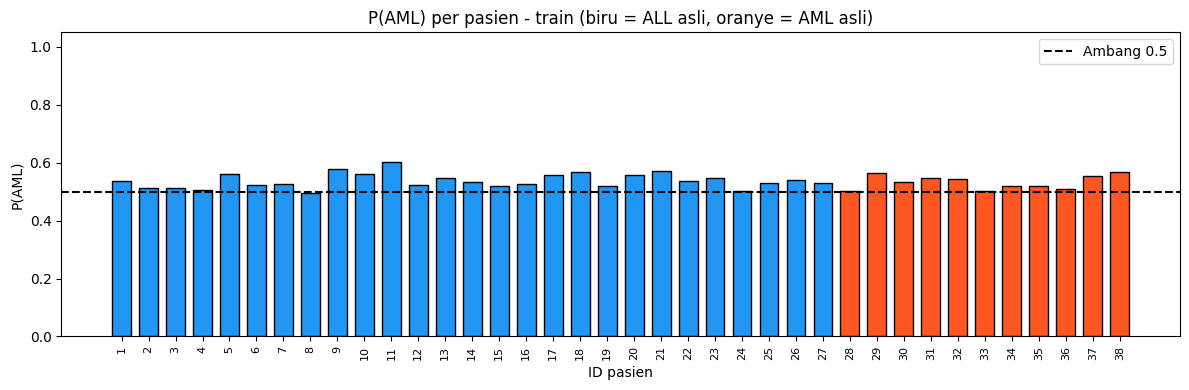

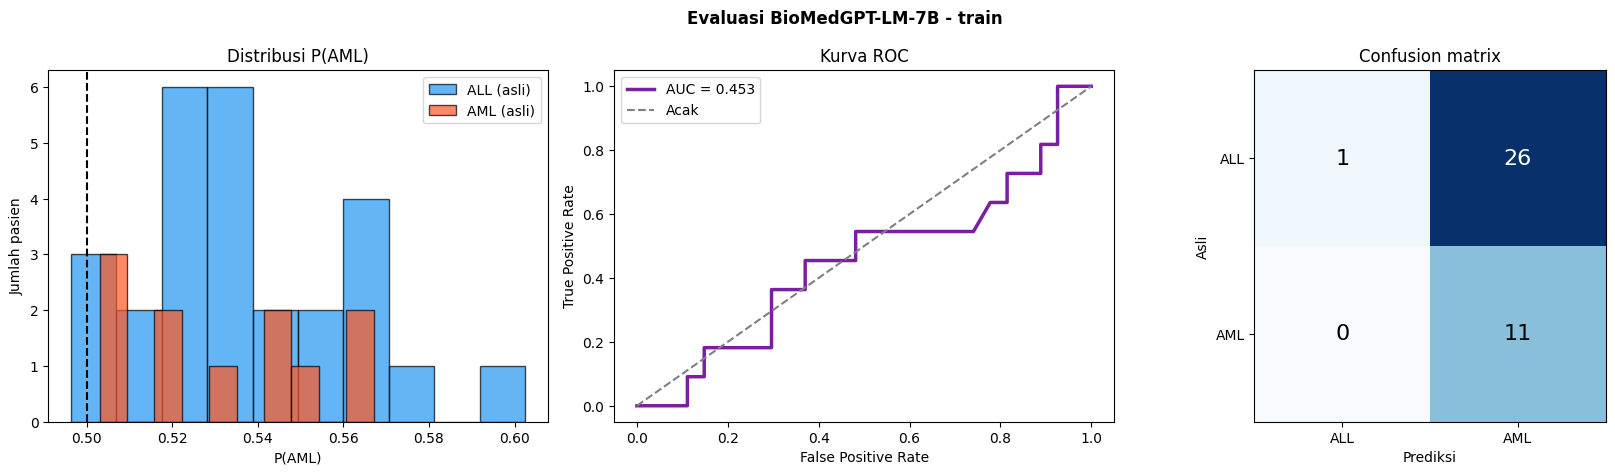

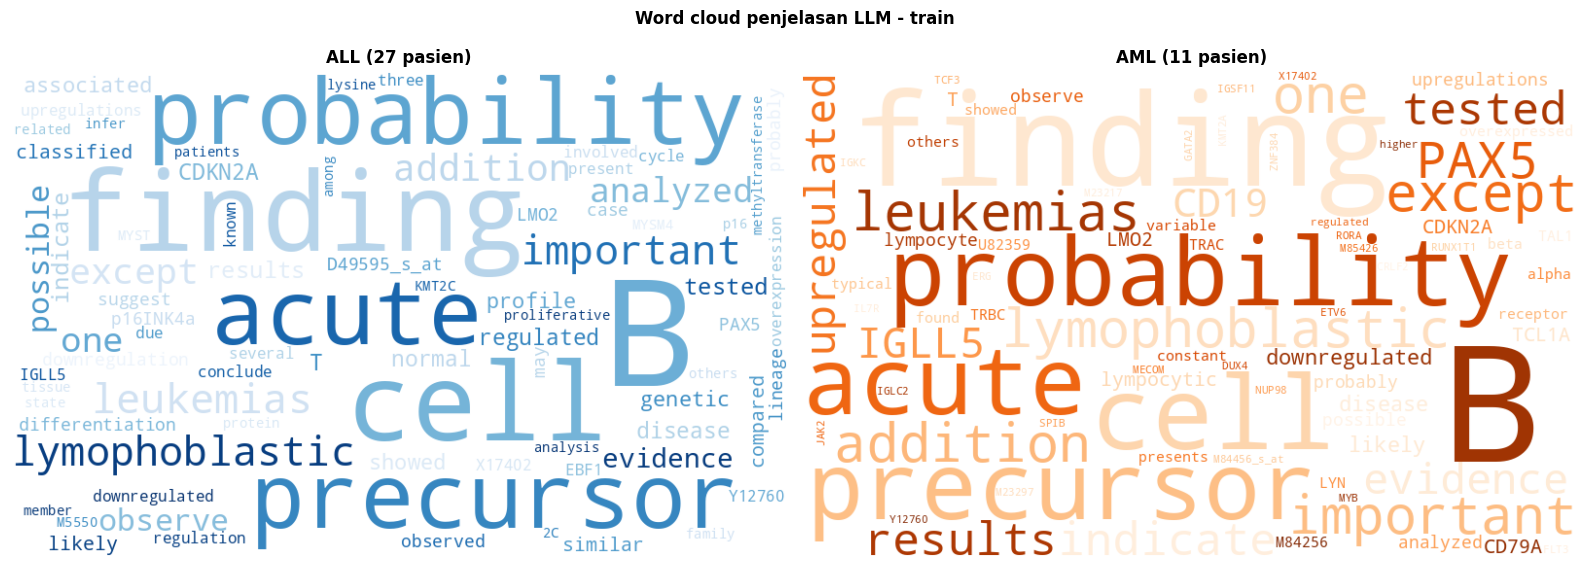

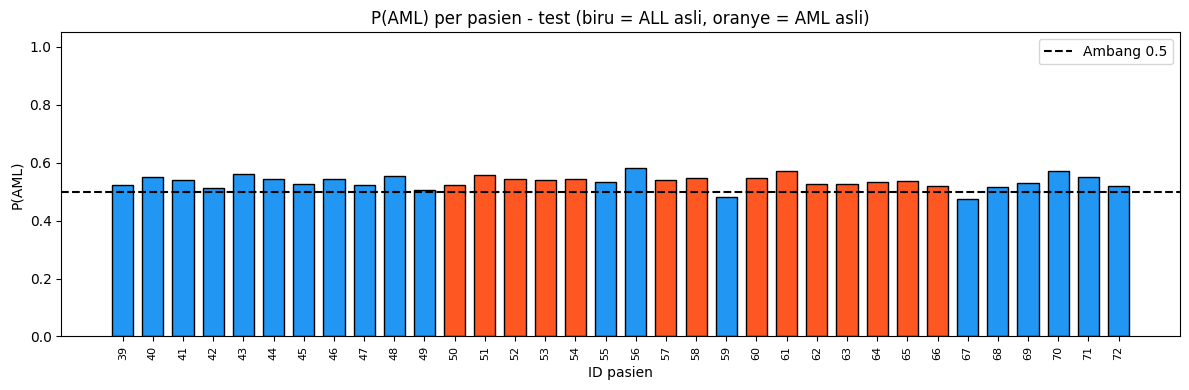

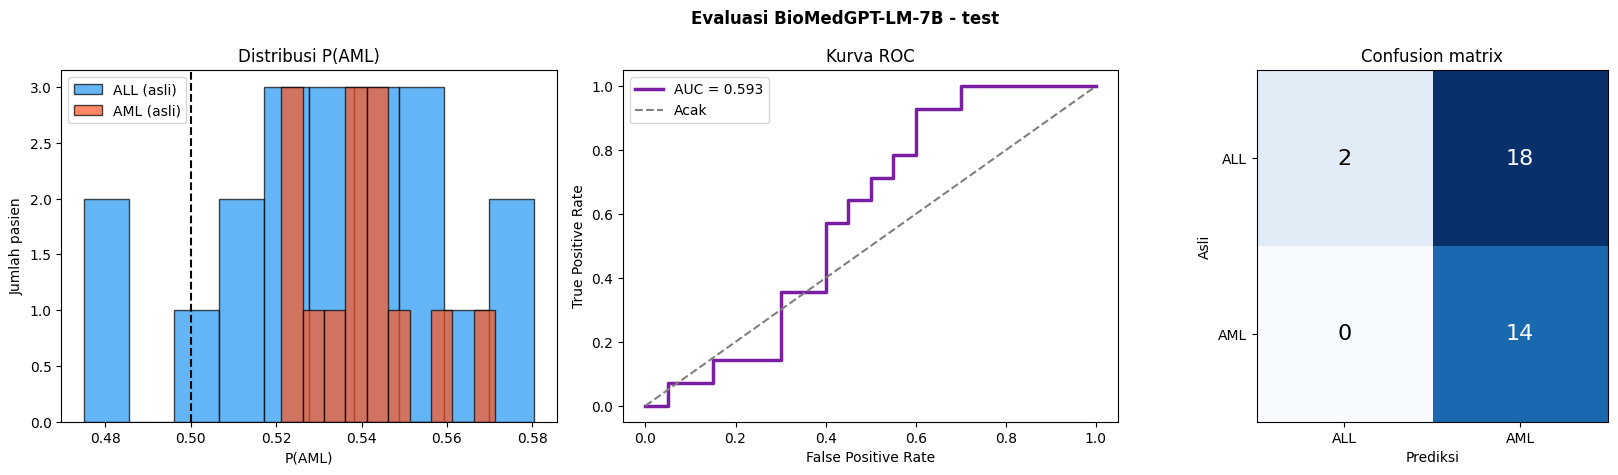

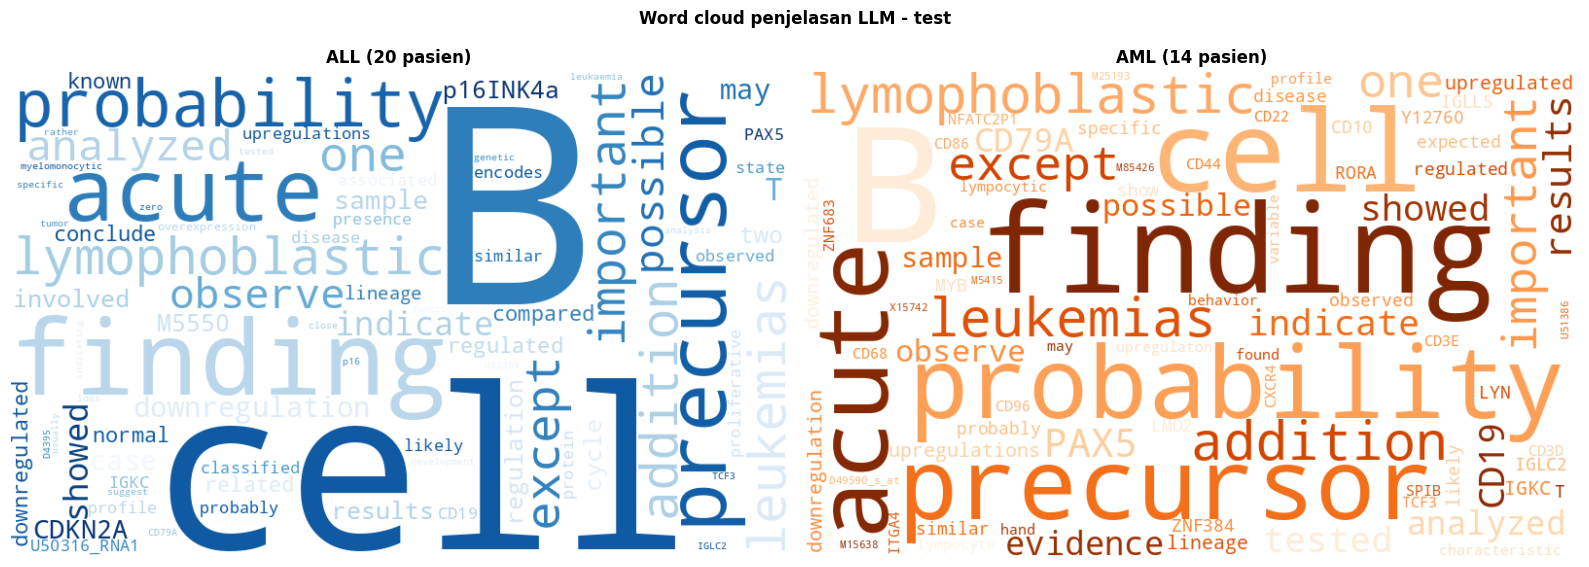

In [ ]:
COLOR = {"ALL": "#2196F3", "AML": "#FF5722"}


def plot_prob_bars(df, split_name):
    """Batang P(AML) per pasien, diwarnai berdasarkan label asli."""
    d = df[df["prediction"] != "ERROR"].sort_values("patient_id")
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(range(len(d)), d["prob_aml"], color=[COLOR[l] for l in d["real_label"]],
           edgecolor="black", width=0.7)
    ax.axhline(PROB_THRESHOLD, color="black", linestyle="--", label=f"Ambang {PROB_THRESHOLD}")
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels(d["patient_id"], rotation=90, fontsize=8)
    ax.set_xlabel("ID pasien")
    ax.set_ylabel("P(AML)")
    ax.set_ylim(0, 1.05)
    ax.set_title(f"P(AML) per pasien - {split_name} (biru = ALL asli, oranye = AML asli)")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/prob_bars_{split_name}.png", dpi=150)
    plt.show()


def plot_evaluation(df, split_name):
    """Histogram probabilitas, kurva ROC, dan confusion matrix dalam satu gambar."""
    d = df[df["prediction"] != "ERROR"]
    y_true = (d["real_label"] == "AML").astype(int).values
    y_pred = (d["prediction"] == "AML").astype(int).values
    proba  = d["prob_aml"].astype(float).values

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

    # (1) distribusi P(AML) per kelas
    for cls in CLASS_NAMES:
        axes[0].hist(d.loc[d["real_label"] == cls, "prob_aml"], bins=10, alpha=0.7,
                     color=COLOR[cls], edgecolor="black", label=f"{cls} (asli)")
    axes[0].axvline(PROB_THRESHOLD, color="black", linestyle="--")
    axes[0].set(title="Distribusi P(AML)", xlabel="P(AML)", ylabel="Jumlah pasien")
    axes[0].legend()

    # (2) kurva ROC
    if len(np.unique(y_true)) == 2:
        fpr, tpr, _ = roc_curve(y_true, proba)
        axes[1].plot(fpr, tpr, color="#7B1FA2", lw=2.5,
                     label=f"AUC = {roc_auc_score(y_true, proba):.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Acak")
    axes[1].set(title="Kurva ROC", xlabel="False Positive Rate", ylabel="True Positive Rate")
    axes[1].legend()

    # (3) confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    axes[2].imshow(cm, cmap="Blues")
    axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(CLASS_NAMES)
    axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(CLASS_NAMES)
    axes[2].set(title="Confusion matrix", xlabel="Prediksi", ylabel="Asli")
    for r in range(2):
        for c in range(2):
            axes[2].text(c, r, cm[r, c], ha="center", va="center", fontsize=16,
                         color="white" if cm[r, c] > cm.max() / 2 else "black")

    fig.suptitle(f"Evaluasi BioMedGPT-LM-7B - {split_name}", fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/evaluasi_{split_name}.png", dpi=150)
    plt.show()


def plot_wordcloud(df, split_name):
    """Word cloud penjelasan LLM, dipisah per kelas asli."""
    from wordcloud import WordCloud, STOPWORDS

    stopwords = STOPWORDS.union({
        "patient", "gene", "genes", "expression", "high", "low", "highly", "lowly",
        "expressed", "level", "levels", "value", "values", "marker", "markers",
        "classification", "aml", "all", "this", "has", "the",
    })
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, cls, cmap in zip(axes, CLASS_NAMES, ["Blues", "Oranges"]):
        text = " ".join(df.loc[df["real_label"] == cls, "explanation"].dropna())
        if text.strip():
            wc = WordCloud(width=800, height=500, background_color="white", colormap=cmap,
                           stopwords=stopwords, max_words=80, collocations=False).generate(text)
            ax.imshow(wc, interpolation="bilinear")
        ax.axis("off")
        ax.set_title(f"{cls} ({(df['real_label'] == cls).sum()} pasien)", fontweight="bold")
    fig.suptitle(f"Word cloud penjelasan LLM - {split_name}", fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/wordcloud_{split_name}.png", dpi=150)
    plt.show()


for name, df in results.items():
    plot_prob_bars(df, name)
    plot_evaluation(df, name)
    plot_wordcloud(df, name)

## **Langkah 12 — Simpan dan unduh hasil**

Semua hasil digabung menjadi satu file `hasil_gabungan.csv`. Kolom-kolomnya:

| Kolom | Isi |
|---|---|
| `patient_id` | ID pasien pada dataset |
| `split` | `train` atau `test` |
| `real_label` / `prediction` | Label asli / prediksi LLM |
| `correct` | Prediksi benar atau salah |
| `prob_aml` / `confidence` | P(AML) dan keyakinan model |
| `explanation` | Teks penjelasan yang dihasilkan LLM |
| `n_words` | Jumlah kata penjelasan |

In [ ]:
all_results = pd.concat(results.values(), ignore_index=True)
all_results.to_csv(f"{OUTPUT_DIR}/hasil_gabungan.csv", index=False)
summary.to_csv(f"{OUTPUT_DIR}/ringkasan_metrik.csv", index=False)

print("File tersimpan di", OUTPUT_DIR)
print(sorted(os.listdir(OUTPUT_DIR)))
display(all_results.head())

# Unduh semua hasil dalam satu zip
import shutil
shutil.make_archive("/content/hasil_klasifikasi", "zip", OUTPUT_DIR)
from google.colab import files
files.download("/content/hasil_klasifikasi.zip")

File tersimpan di /content/hasil
['evaluasi_test.png', 'evaluasi_train.png', 'hasil_gabungan.csv', 'hasil_test.csv', 'hasil_train.csv', 'prob_bars_test.png', 'prob_bars_train.png', 'ringkasan_metrik.csv', 'wordcloud_test.png', 'wordcloud_train.png']


,patient_id,split,real_label,prediction,prob_aml,confidence,explanation,correct,n_words
0,1,train,ALL,AML,0.5382,0.5382,a high probability of having B-cell precursor ...,False,59
1,2,train,ALL,AML,0.5121,0.5121,a high probability of having B-cell precursor ...,False,68
2,3,train,ALL,AML,0.5111,0.5111,a high probability of having B-cell precursor ...,False,33
3,4,train,ALL,AML,0.5049,0.5049,a high probability of having B-cell precursor ...,False,51
4,5,train,ALL,AML,0.5602,0.5602,a high probability of having B-cell precursor ...,False,59


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>